<a href="https://colab.research.google.com/github/michelleuu/IAT360-Driver-Drowsiness-Computer-Vision-Project-/blob/main/DriverDrowsinessYolo8.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## IAT 360 Computer Vision Project

In [18]:
%pip install ultralytics

Note: you may need to restart the kernel to use updated packages.


You should consider upgrading via the 'C:\Users\liang\AppData\Local\Programs\Python\Python310\python.exe -m pip install --upgrade pip' command.


## Import Libraries


In [19]:
import os
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path
from PIL import Image
from ultralytics import YOLO

## Prepare dataset

### Set dataset path

Path for local

In [20]:
from pathlib import Path

dataset_path = Path("dataset")

print("Dataset exists:", dataset_path.exists())
print("Current working directory:", Path.cwd())

if dataset_path.exists():
    print("\nDataset contents:")
    for item in dataset_path.iterdir():
        print(item.name)

Dataset exists: True
Current working directory: C:\Users\liang\OneDrive\Desktop\iat360\CVproject-driverDrowsiness

Dataset contents:
.DS_Store
data.yaml
README.roboflow.txt
train
valid


####Path for google drive

In [ ]:
from pathlib import Path
from google.colab import drive
drive.mount('/content/drive')

dataset_path = Path("/content/drive/MyDrive/IAT360_Driver_Drowsiness/dataset")

print("Dataset exists:", dataset_path.exists())
print("Current working directory:", Path.cwd())

if dataset_path.exists():
    print("\nDataset contents:")
    for item in dataset_path.iterdir():
        print(item.name)

Mounted at /content/drive
Dataset exists: True
Current working directory: /content

Dataset contents:
.DS_Store
train
valid
README.roboflow.txt
data.yaml


####Checking:

In [24]:
with open(dataset_path / "data.yaml", "r") as file:
    print(file.read())

names:
- eye_closed
- eye_open
- head_dropped
- head_straight
- no_yawn
- yawn
nc: 6
path: C:\Users\liang\OneDrive\Desktop\iat360\CVproject-driverDrowsiness\dataset
roboflow:
  license: CC BY 4.0
  project: kantukv2-hihkc
  url: https://app.roboflow.com/michelles-workspace-b7mvu/kantukv2-hihkc/1
  version: 1
  workspace: michelles-workspace-b7mvu
train: train/images
val: valid/images



### Check Dataset Split: 90% Training, 10% Validation, 0% Test

In [21]:
split_counts = {}

for split in ["train", "valid", "test"]:
    image_folder = dataset_path / split / "images"
    label_folder = dataset_path / split / "labels"

    images = list(image_folder.glob("*.jpg")) + list(image_folder.glob("*.png"))
    labels = list(label_folder.glob("*.txt"))

    split_counts[split] = len(images)

    print(f"\n{split}:")
    print("Images:", len(images))
    print("Labels:", len(labels))

# Calculate dataset split percentages
total_images = sum(split_counts.values())

print("\nDataset Split Percentages:")
for split, count in split_counts.items():
    percentage = (count / total_images * 100) if total_images > 0 else 0
    print(f"{split}: {percentage:.2f}%")

# Check if test set is empty
assert split_counts["test"] == 0, "Test set is not empty!"
print("\nTest set confirmed: 0%")


train:
Images: 3457
Labels: 3457

valid:
Images: 384
Labels: 384

test:
Images: 0
Labels: 0

Dataset Split Percentages:
train: 90.00%
valid: 10.00%
test: 0.00%

Test set confirmed: 0%


### Check class distribution

In [22]:
import yaml
from collections import Counter

# Read class names from data.yaml
with open(dataset_path / "data.yaml", "r") as file:
    config = yaml.safe_load(file)

# Count annotations for each class
class_counts = Counter()

for split in ["train", "valid"]:
    label_folder = dataset_path / split / "labels"

    for label_file in label_folder.glob("*.txt"):
        for line in label_file.read_text().splitlines():
            if not line.strip():
                continue

            class_id = int(line.split()[0])
            class_counts[class_id] += 1

# Display class distribution
for class_id, class_name in enumerate(config["names"]):
    print(f"{class_name}: {class_counts[class_id]}")

eye_closed: 1773
eye_open: 2066
head_dropped: 1134
head_straight: 2707
no_yawn: 2201
yawn: 1638


## Import yolo Model

In [23]:
from ultralytics import YOLO
model = YOLO("yolov8s.pt")
print("YOLOv8 model loaded successfully!")

YOLOv8 model loaded successfully!


### Train baseline YOLOv8 model

In [ ]:
from ultralytics import YOLO

model_baseline = YOLO("yolov8s.pt")

results_baseline = model_baseline.train(
    data=str(dataset_path / "data.yaml"),
    epochs=5,
    patience=5,
    batch=8,
    lr0=0.0005,
    optimizer="AdamW",
    imgsz=640,
    device="mps",
    workers=0,
    project="Driver_Drowsiness",
    name="baseline_adamw",
    seed=42
)

New https://pypi.org/project/ultralytics/8.4.201 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.183 🚀 Python-3.14.7 torch-2.14.1 MPS (Apple M4 Pro)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=dataset/data.yaml, degrees=0.0, deterministic=True, device=mps, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=5, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.0005, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8s.pt, momentum=0.937, mosaic=1.0, multi

/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/torch/autograd/graph.py:1072: UserWarning: scatter_reduce_mps does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /Users/runner/work/pytorch/pytorch/aten/src/ATen/Context.cpp:190.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass
/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/torch/autograd/graph.py:1072: UserWarning: index_put_with_accumulate_mps does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operatio

        1/5      5.66G      1.375      1.205      1.552         15        640: 100% ━━━━━━━━━━━━ 400/400 2.8it/s 2:21
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 24/24 3.4it/s 7.0s
                   all        380       1140      0.774      0.792      0.855      0.522

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
        2/5      5.63G      1.148     0.7513      1.251         24        640: 0% ──────────── 0/400  0.6s

/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/torch/autograd/graph.py:1072: UserWarning: scatter_reduce_mps does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /Users/runner/work/pytorch/pytorch/aten/src/ATen/Context.cpp:190.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass
/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/torch/autograd/graph.py:1072: UserWarning: index_put_with_accumulate_mps does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operatio

        2/5      5.66G      1.209     0.8284       1.39         15        640: 100% ━━━━━━━━━━━━ 400/400 2.9it/s 2:17
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 24/24 3.4it/s 7.0s
                   all        380       1140       0.88      0.852      0.905      0.591

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
        3/5      5.63G       1.22     0.7901      1.326         24        640: 0% ──────────── 0/400  0.6s

/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/torch/autograd/graph.py:1072: UserWarning: scatter_reduce_mps does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /Users/runner/work/pytorch/pytorch/aten/src/ATen/Context.cpp:190.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass
/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/torch/autograd/graph.py:1072: UserWarning: index_put_with_accumulate_mps does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operatio

        3/5      5.58G       1.15     0.7173      1.318         15        640: 100% ━━━━━━━━━━━━ 400/400 3.0it/s 2:16
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 24/24 3.4it/s 7.0s
                   all        380       1140      0.892      0.895      0.918        0.6

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
        4/5      5.56G      1.098     0.6519      1.339         24        640: 0% ──────────── 0/400  0.6s

/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/torch/autograd/graph.py:1072: UserWarning: scatter_reduce_mps does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /Users/runner/work/pytorch/pytorch/aten/src/ATen/Context.cpp:190.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass
/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/torch/autograd/graph.py:1072: UserWarning: index_put_with_accumulate_mps does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operatio

        4/5      5.51G      1.108     0.6335      1.272         15        640: 100% ━━━━━━━━━━━━ 400/400 3.0it/s 2:16
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 24/24 3.5it/s 6.9s
                   all        380       1140      0.908      0.884       0.93      0.609

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
        5/5      5.57G      1.197     0.5688      1.197         24        640: 0% ──────────── 0/400  0.6s

/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/torch/autograd/graph.py:1072: UserWarning: scatter_reduce_mps does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /Users/runner/work/pytorch/pytorch/aten/src/ATen/Context.cpp:190.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass
/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/torch/autograd/graph.py:1072: UserWarning: index_put_with_accumulate_mps does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operatio

        5/5      6.51G      1.058     0.5747      1.234         15        640: 100% ━━━━━━━━━━━━ 400/400 2.9it/s 2:16
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 24/24 3.4it/s 7.0s
                   all        380       1140       0.94      0.898      0.943      0.628

5 epochs completed in 0.201 hours.
Optimizer stripped from /Users/michellezhu/Desktop/Fall 2026/IAT360 Codes/ComputerVisionFinalProject/runs/detect/Driver_Drowsiness/baseline_adamw/weights/last.pt, 22.5MB
Optimizer stripped from /Users/michellezhu/Desktop/Fall 2026/IAT360 Codes/ComputerVisionFinalProject/runs/detect/Driver_Drowsiness/baseline_adamw/weights/best.pt, 22.5MB

Validating /Users/michellezhu/Desktop/Fall 2026/IAT360 Codes/ComputerVisionFinalProject/runs/detect/Driver_Drowsiness/baseline_adamw/weights/best.pt...
Ultralytics 8.4.183 🚀 Python-3.14.7 torch-2.14.1 MPS (Apple M4 Pro)
Model summary (fused): 72 layers, 11,127,906 parameters, 0 gradients,

### Evaluate baseline performance


In [ ]:
metrics = model.val(project="Driver_Drowsiness")  # no other arguments needed, dataset and settings remembered
metrics.box.map    # map50-95
metrics.box.map50  # map50
metrics.box.map75  # map75
metrics.box.maps   # a list contains map50-95 of each category
metrics.box.mp    # P
metrics.box.mr

Ultralytics 8.4.183 🚀 Python-3.14.7 torch-2.14.1 CPU (Apple M4 Pro)
Model summary (fused): 72 layers, 11,127,906 parameters, 0 gradients, 28.4 GFLOPs
val: Fast image access ✅ (ping: 0.1±0.1 ms, read: 246.2±145.4 MB/s, size: 46.8 KB)
val: Scanning /Users/michellezhu/Desktop/Fall 2026/IAT360 Codes/ComputerVisionFinalProject/dataset/valid/labels.cache... 384 images, 0 backgrounds, 4 corrupt: 100% ━━━━━━━━━━━━ 384/384 55.5Mit/s 0.0s
val: /Users/michellezhu/Desktop/Fall 2026/IAT360 Codes/ComputerVisionFinalProject/dataset/valid/images/cropped_53-2-_aug2_jpg.rf.a1d11dfa0d785d1dfff2453a8ede5057.jpg: ignoring corrupt image/label: labels mix segment and detection rows
val: /Users/michellezhu/Desktop/Fall 2026/IAT360 Codes/ComputerVisionFinalProject/dataset/valid/images/cropped_63_aug0_jpg.rf.b3c870740ac87599a19796f0a4008ae2.jpg: ignoring corrupt image/label: labels mix segment and detection rows
val: /Users/michellezhu/Desktop/Fall 2026/IAT360 Codes/ComputerVisionFinalProject/dataset/valid/imag

np.float64(0.8974742098935645)

In [ ]:
model_baseline = YOLO(
    "runs/detect/Driver_Drowsiness/baseline_adamw/weights/best.pt"
)

### Check model predictions on images from the validation dataset

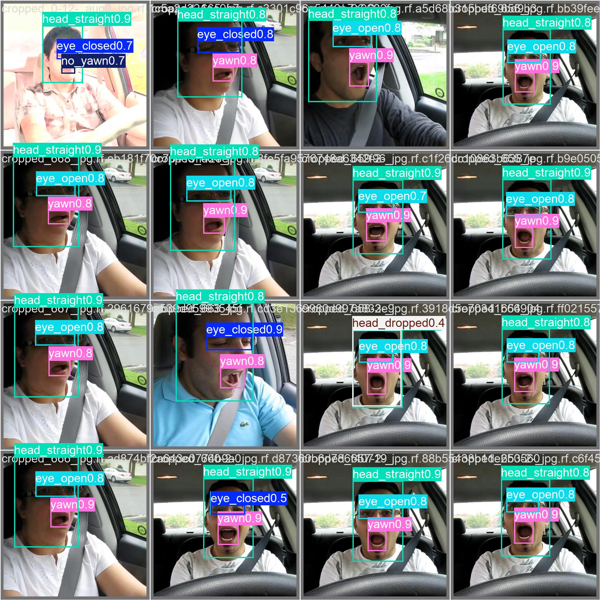

In [ ]:
from PIL import Image
from IPython.display import display

img = Image.open(
    "runs/detect/Driver_Drowsiness/baseline_adamw/val_batch0_pred.jpg"
)

img.thumbnail((600, 600))
display(img)

### Confusion matrix

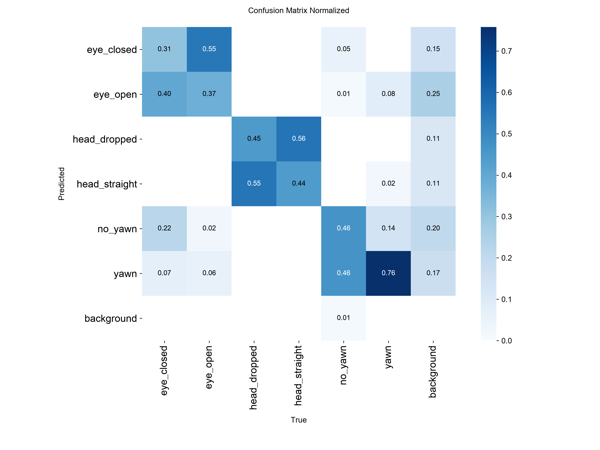

In [ ]:
from PIL import Image
from IPython.display import display

img = Image.open(
    "runs/detect/Driver_Drowsiness/baseline_adamw/confusion_matrix_normalized.png"
)

img.thumbnail((600, 600))
display(img)

### Hyperparameter tuning


#### Michelle — Learning Rate

Baseline learning rate: 0.0005

Learning rate values to test:

- 0.0001

- 0.001

- 0.005

In [ ]:
# Learning Rate = 0.0001

model_lr1 = YOLO("yolov8s.pt")

results_lr1 = model_lr1.train(
    data=str(dataset_path / "data.yaml"),
    epochs=5,
    patience=5,
    batch=8,
    lr0=0.0001,
    optimizer="AdamW",
    imgsz=640,
    device="mps",
    workers=0,
    project="Driver_Drowsiness",
    name="lr_0.0001_adamw",
    seed=42
)

New https://pypi.org/project/ultralytics/8.4.201 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.183 🚀 Python-3.14.7 torch-2.14.1 MPS (Apple M4 Pro)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=dataset/data.yaml, degrees=0.0, deterministic=True, device=mps, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=5, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.0001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8s.pt, momentum=0.937, mosaic=1.0, multi

/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/torch/autograd/graph.py:1072: UserWarning: scatter_reduce_mps does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /Users/runner/work/pytorch/pytorch/aten/src/ATen/Context.cpp:190.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass
/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/torch/autograd/graph.py:1072: UserWarning: index_put_with_accumulate_mps does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operatio

        1/5      6.59G      1.376      1.252       1.55         15        640: 100% ━━━━━━━━━━━━ 400/400 2.7it/s 2:29
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 24/24 3.2it/s 7.6s
                   all        380       1140      0.788       0.78      0.856      0.547

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
        2/5      5.71G      1.002     0.7772      1.161         24        640: 0% ──────────── 0/400  0.6s

/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/torch/autograd/graph.py:1072: UserWarning: scatter_reduce_mps does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /Users/runner/work/pytorch/pytorch/aten/src/ATen/Context.cpp:190.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass
/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/torch/autograd/graph.py:1072: UserWarning: index_put_with_accumulate_mps does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operatio

        2/5      6.66G      1.186      0.813      1.329         15        640: 100% ━━━━━━━━━━━━ 400/400 2.8it/s 2:23
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 24/24 3.4it/s 7.1s
                   all        380       1140      0.903      0.849      0.905      0.593

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
        3/5      5.68G      1.114     0.7853      1.211         24        640: 0% ──────────── 0/400  0.6s

/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/torch/autograd/graph.py:1072: UserWarning: scatter_reduce_mps does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /Users/runner/work/pytorch/pytorch/aten/src/ATen/Context.cpp:190.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass
/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/torch/autograd/graph.py:1072: UserWarning: index_put_with_accumulate_mps does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operatio

        3/5      6.56G      1.128     0.6935      1.255         15        640: 100% ━━━━━━━━━━━━ 400/400 2.9it/s 2:16
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 24/24 3.4it/s 7.0s
                   all        380       1140      0.891      0.901      0.929      0.622

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
        4/5      5.68G      1.034     0.5496      1.204         24        640: 0% ──────────── 0/400  0.5s

/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/torch/autograd/graph.py:1072: UserWarning: scatter_reduce_mps does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /Users/runner/work/pytorch/pytorch/aten/src/ATen/Context.cpp:190.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass
/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/torch/autograd/graph.py:1072: UserWarning: index_put_with_accumulate_mps does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operatio

        4/5      6.61G      1.091     0.6198      1.217         15        640: 100% ━━━━━━━━━━━━ 400/400 2.8it/s 2:22
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 24/24 3.4it/s 7.0s
                   all        380       1140       0.89      0.898      0.939      0.637

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
        5/5      5.68G      1.151     0.5339      1.135         24        640: 0% ──────────── 0/400  0.5s

/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/torch/autograd/graph.py:1072: UserWarning: scatter_reduce_mps does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /Users/runner/work/pytorch/pytorch/aten/src/ATen/Context.cpp:190.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass
/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/torch/autograd/graph.py:1072: UserWarning: index_put_with_accumulate_mps does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operatio

        5/5      6.71G      1.061     0.5811      1.195         15        640: 100% ━━━━━━━━━━━━ 400/400 2.9it/s 2:16
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 24/24 3.4it/s 7.0s
                   all        380       1140      0.914      0.892      0.947      0.641

5 epochs completed in 0.207 hours.
Optimizer stripped from /Users/michellezhu/Desktop/Fall 2026/IAT360 Codes/ComputerVisionFinalProject/runs/detect/Driver_Drowsiness/lr_0.0001_adamw/weights/last.pt, 22.5MB
Optimizer stripped from /Users/michellezhu/Desktop/Fall 2026/IAT360 Codes/ComputerVisionFinalProject/runs/detect/Driver_Drowsiness/lr_0.0001_adamw/weights/best.pt, 22.5MB

Validating /Users/michellezhu/Desktop/Fall 2026/IAT360 Codes/ComputerVisionFinalProject/runs/detect/Driver_Drowsiness/lr_0.0001_adamw/weights/best.pt...
Ultralytics 8.4.183 🚀 Python-3.14.7 torch-2.14.1 MPS (Apple M4 Pro)
Model summary (fused): 72 layers, 11,127,906 parameters, 0 gradien

In [ ]:
# Learning Rate = 0.001

model_lr2 = YOLO("yolov8s.pt")

results_lr2 = model_lr2.train(
    data=str(dataset_path / "data.yaml"),
    epochs=5,
    patience=5,
    batch=8,
    lr0=0.001,
    optimizer="AdamW",
    imgsz=640,
    device="mps",
    workers=0,
    project="Driver_Drowsiness",
    name="lr_0.001_adamw",
    seed=42
)

New https://pypi.org/project/ultralytics/8.4.201 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.183 🚀 Python-3.14.7 torch-2.14.1 MPS (Apple M4 Pro)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=dataset/data.yaml, degrees=0.0, deterministic=True, device=mps, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=5, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8s.pt, momentum=0.937, mosaic=1.0, multi_

/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/torch/autograd/graph.py:1072: UserWarning: scatter_reduce_mps does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /Users/runner/work/pytorch/pytorch/aten/src/ATen/Context.cpp:190.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass
/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/torch/autograd/graph.py:1072: UserWarning: index_put_with_accumulate_mps does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operatio

        1/5      6.75G      1.375        1.2      1.483         15        640: 100% ━━━━━━━━━━━━ 400/400 2.8it/s 2:22
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 24/24 3.4it/s 7.0s
                   all        380       1140      0.799      0.802      0.857      0.536

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
        2/5      5.72G      1.227     0.7927      1.191         24        640: 0% ──────────── 0/400  0.5s

/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/torch/autograd/graph.py:1072: UserWarning: scatter_reduce_mps does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /Users/runner/work/pytorch/pytorch/aten/src/ATen/Context.cpp:190.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass
/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/torch/autograd/graph.py:1072: UserWarning: index_put_with_accumulate_mps does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operatio

        2/5      6.67G      1.232     0.8428      1.333         15        640: 100% ━━━━━━━━━━━━ 400/400 2.9it/s 2:18
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 24/24 3.4it/s 7.1s
                   all        380       1140      0.859      0.853      0.879      0.558

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
        3/5      6.72G      1.242     0.7789      1.281         24        640: 0% ──────────── 0/400  0.6s

/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/torch/autograd/graph.py:1072: UserWarning: scatter_reduce_mps does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /Users/runner/work/pytorch/pytorch/aten/src/ATen/Context.cpp:190.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass
/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/torch/autograd/graph.py:1072: UserWarning: index_put_with_accumulate_mps does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operatio

        3/5      6.75G      1.181     0.7368      1.287         15        640: 100% ━━━━━━━━━━━━ 400/400 2.9it/s 2:17
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 24/24 3.4it/s 7.1s
                   all        380       1140      0.884       0.88      0.922      0.599

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
        4/5      5.72G      1.123      0.676      1.284         24        640: 0% ──────────── 0/400  0.5s

/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/torch/autograd/graph.py:1072: UserWarning: scatter_reduce_mps does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /Users/runner/work/pytorch/pytorch/aten/src/ATen/Context.cpp:190.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass
/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/torch/autograd/graph.py:1072: UserWarning: index_put_with_accumulate_mps does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operatio

        4/5      6.76G      1.128     0.6593      1.246         15        640: 100% ━━━━━━━━━━━━ 400/400 2.9it/s 2:17
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 24/24 3.4it/s 7.1s
                   all        380       1140      0.906      0.895      0.932      0.619

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
        5/5      6.72G      1.257     0.5794      1.204         24        640: 0% ──────────── 0/400  0.6s

/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/torch/autograd/graph.py:1072: UserWarning: scatter_reduce_mps does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /Users/runner/work/pytorch/pytorch/aten/src/ATen/Context.cpp:190.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass
/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/torch/autograd/graph.py:1072: UserWarning: index_put_with_accumulate_mps does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operatio

        5/5      6.61G      1.077     0.5884      1.205         15        640: 100% ━━━━━━━━━━━━ 400/400 2.9it/s 2:17
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 24/24 3.4it/s 7.1s
                   all        380       1140      0.888       0.92      0.945      0.627

5 epochs completed in 0.203 hours.
Optimizer stripped from /Users/michellezhu/Desktop/Fall 2026/IAT360 Codes/ComputerVisionFinalProject/runs/detect/Driver_Drowsiness/lr_0.001_adamw/weights/last.pt, 22.5MB
Optimizer stripped from /Users/michellezhu/Desktop/Fall 2026/IAT360 Codes/ComputerVisionFinalProject/runs/detect/Driver_Drowsiness/lr_0.001_adamw/weights/best.pt, 22.5MB

Validating /Users/michellezhu/Desktop/Fall 2026/IAT360 Codes/ComputerVisionFinalProject/runs/detect/Driver_Drowsiness/lr_0.001_adamw/weights/best.pt...
Ultralytics 8.4.183 🚀 Python-3.14.7 torch-2.14.1 MPS (Apple M4 Pro)
Model summary (fused): 72 layers, 11,127,906 parameters, 0 gradients,

In [ ]:
# Learning Rate = 0.005

model_lr2 = YOLO("yolov8s.pt")

results_lr2 = model_lr2.train(
    data=str(dataset_path / "data.yaml"),
    epochs=5,
    patience=5,
    batch=8,
    lr0=0.005,
    optimizer="AdamW",
    imgsz=640,
    device="mps",
    workers=0,
    project="Driver_Drowsiness",
    name="lr_0.005_adamw",
    seed=42
)

New https://pypi.org/project/ultralytics/8.4.201 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.183 🚀 Python-3.14.7 torch-2.14.1 MPS (Apple M4 Pro)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=dataset/data.yaml, degrees=0.0, deterministic=True, device=mps, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=5, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.005, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8s.pt, momentum=0.937, mosaic=1.0, multi_

/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/torch/autograd/graph.py:1072: UserWarning: scatter_reduce_mps does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /Users/runner/work/pytorch/pytorch/aten/src/ATen/Context.cpp:190.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass
/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/torch/autograd/graph.py:1072: UserWarning: index_put_with_accumulate_mps does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operatio

        1/5      6.83G      1.486      1.353      1.655         15        640: 100% ━━━━━━━━━━━━ 400/400 2.8it/s 2:22
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 24/24 3.3it/s 7.4s
                   all        380       1140      0.684      0.689      0.714        0.4

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
        2/5      6.79G      1.442      1.025      1.466         24        640: 0% ──────────── 0/400  0.6s

/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/torch/autograd/graph.py:1072: UserWarning: scatter_reduce_mps does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /Users/runner/work/pytorch/pytorch/aten/src/ATen/Context.cpp:190.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass
/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/torch/autograd/graph.py:1072: UserWarning: index_put_with_accumulate_mps does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operatio

        2/5      6.83G       1.37      1.021      1.576         15        640: 100% ━━━━━━━━━━━━ 400/400 2.9it/s 2:18
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 24/24 3.4it/s 7.1s
                   all        380       1140      0.745      0.656      0.685      0.391

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
        3/5      6.78G      1.301     0.8806      1.417         24        640: 0% ──────────── 0/400  0.6s

/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/torch/autograd/graph.py:1072: UserWarning: scatter_reduce_mps does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /Users/runner/work/pytorch/pytorch/aten/src/ATen/Context.cpp:190.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass
/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/torch/autograd/graph.py:1072: UserWarning: index_put_with_accumulate_mps does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operatio

        3/5       6.8G      1.294       0.88      1.499         15        640: 100% ━━━━━━━━━━━━ 400/400 2.9it/s 2:17
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 24/24 3.4it/s 7.0s
                   all        380       1140      0.868      0.866      0.904      0.551

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
        4/5      6.76G      1.226     0.7969      1.559         24        640: 0% ──────────── 0/400  0.6s

/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/torch/autograd/graph.py:1072: UserWarning: scatter_reduce_mps does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /Users/runner/work/pytorch/pytorch/aten/src/ATen/Context.cpp:190.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass
/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/torch/autograd/graph.py:1072: UserWarning: index_put_with_accumulate_mps does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operatio

        4/5      6.79G      1.219     0.7727      1.427         15        640: 100% ━━━━━━━━━━━━ 400/400 2.9it/s 2:16
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 24/24 3.4it/s 7.0s
                   all        380       1140      0.867      0.866      0.902      0.587

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
        5/5      6.76G      1.134     0.6658      1.275         24        640: 0% ──────────── 0/400  0.6s

/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/torch/autograd/graph.py:1072: UserWarning: scatter_reduce_mps does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /Users/runner/work/pytorch/pytorch/aten/src/ATen/Context.cpp:190.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass
/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/torch/autograd/graph.py:1072: UserWarning: index_put_with_accumulate_mps does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operatio

        5/5      6.79G      1.154     0.6694      1.375         15        640: 100% ━━━━━━━━━━━━ 400/400 3.0it/s 2:15
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 24/24 3.4it/s 7.0s
                   all        380       1140      0.933      0.878      0.937       0.61

5 epochs completed in 0.202 hours.
Optimizer stripped from /Users/michellezhu/Desktop/Fall 2026/IAT360 Codes/ComputerVisionFinalProject/runs/detect/Driver_Drowsiness/lr_0.005_adamw/weights/last.pt, 22.5MB
Optimizer stripped from /Users/michellezhu/Desktop/Fall 2026/IAT360 Codes/ComputerVisionFinalProject/runs/detect/Driver_Drowsiness/lr_0.005_adamw/weights/best.pt, 22.5MB

Validating /Users/michellezhu/Desktop/Fall 2026/IAT360 Codes/ComputerVisionFinalProject/runs/detect/Driver_Drowsiness/lr_0.005_adamw/weights/best.pt...
Ultralytics 8.4.183 🚀 Python-3.14.7 torch-2.14.1 MPS (Apple M4 Pro)
Model summary (fused): 72 layers, 11,127,906 parameters, 0 gradients,

In [ ]:
import pandas as pd
from pathlib import Path

results_dir = Path("runs/detect/Driver_Drowsiness")

experiments = {
    "baseline_adamw": 0.0005,
    "lr_0.0001_adamw": 0.0001,
    "lr_0.001_adamw": 0.0010,
    "lr_0.005_adamw": 0.0050
}

results = []

for name, lr in experiments.items():
    df = pd.read_csv(results_dir / name / "results.csv")
    df.columns = df.columns.str.strip()

    # Select best epoch based on mAP50-95
    best = df.loc[df["metrics/mAP50-95(B)"].idxmax()]

    results.append({
        "Learning Rate": lr,
        "Precision": best["metrics/precision(B)"],
        "Recall": best["metrics/recall(B)"],
        "mAP50": best["metrics/mAP50(B)"],
        "mAP50-95": best["metrics/mAP50-95(B)"]
    })

df = pd.DataFrame(results)

display(
    df.style
    .format({
        "Learning Rate": "{:.4f}",
        "Precision": "{:.3f}",
        "Recall": "{:.3f}",
        "mAP50": "{:.3f}",
        "mAP50-95": "{:.3f}"
    })
    .set_table_styles([
        {"selector": "tbody tr:nth-child(even)", "props": [("background-color", "#444444")]},
        {"selector": "td", "props": [("padding", "10px 18px"), ("text-align", "center")]}
    ])
)

,Learning Rate,Precision,Recall,mAP50,mAP50-95
0,0.0005,0.940,0.898,0.943,0.628
1,0.0001,0.914,0.892,0.947,0.641
2,0.0010,0.888,0.920,0.945,0.627
3,0.0050,0.933,0.878,0.937,0.610


Three learning rates (0.0001, 0.001, and 0.005) were tested against the baseline learning rate of 0.0005. Other training parameters were kept the same.

Evaluating the table, a learning rate of 0.0001 achieved the highest mAP50 (0.947) and mAP50-95 (0.641). However, the baseline (0.0005) achieved the highest precision (0.940), while 0.001 achieved the highest recall (0.920).

Overall, 0.0001 is the best learning rate because it achieved the highest mAP50 and mAP50-95, indicating better overall object detection performance. However, the performance difference was relatively small compared to the baseline.

#### Yumin — Epochs

Baseline epochs: 5

Epochs values to test:
- 10
- 20
- 30

In [25]:
with open(dataset_path / "data.yaml", "r") as file:
    print(file.read())

names:
- eye_closed
- eye_open
- head_dropped
- head_straight
- no_yawn
- yawn
nc: 6
path: C:\Users\liang\OneDrive\Desktop\iat360\CVproject-driverDrowsiness\dataset
roboflow:
  license: CC BY 4.0
  project: kantukv2-hihkc
  url: https://app.roboflow.com/michelles-workspace-b7mvu/kantukv2-hihkc/1
  version: 1
  workspace: michelles-workspace-b7mvu
train: train/images
val: valid/images



In [26]:
# Epochs = 10
model_e1 = YOLO("yolov8s.pt")
results_e1 = model_e1.train(
    data=str(dataset_path / "data.yaml"),
    epochs=10,
    patience=5,
    batch=8,
    lr0=0.0005,
    optimizer="AdamW",
    imgsz=640,
    device="cuda",
    workers=0,
    project="Driver_Drowsiness",
    name="epochs_10_adamw",
    seed=42
)

Ultralytics 8.4.204  Python-3.10.3 torch-2.7.1+cu118 CUDA:0 (NVIDIA GeForce GTX 1660 SUPER, 6144MiB)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=dataset\data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=10, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.0005, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8s.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=epochs_10_adamw, nbs=64, nms=None, opset=None, optimi

In [27]:
# Epochs = 20
model_e2 = YOLO("yolov8s.pt")
results_e2 = model_e2.train(
    data=str(dataset_path / "data.yaml"),
    epochs=20,
    patience=5,
    batch=8,
    lr0=0.0005,
    optimizer="AdamW",
    imgsz=640,
    device="cuda",
    workers=0,
    project="Driver_Drowsiness",
    name="epochs_20_adamw",
    seed=42
)

Ultralytics 8.4.204  Python-3.10.3 torch-2.7.1+cu118 CUDA:0 (NVIDIA GeForce GTX 1660 SUPER, 6144MiB)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=dataset\data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=20, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.0005, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8s.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=epochs_20_adamw, nbs=64, nms=None, opset=None, optimi

In [28]:
# Epochs = 30
model_e3 = YOLO("yolov8s.pt")
results_e3 = model_e3.train(
    data=str(dataset_path / "data.yaml"),
    epochs=30,
    patience=5,
    batch=8,
    lr0=0.0005,
    optimizer="AdamW",
    imgsz=640,
    device="cuda",
    workers=0,
    project="Driver_Drowsiness",
    name="epochs_30_adamw",
    seed=42
)

Ultralytics 8.4.204  Python-3.10.3 torch-2.7.1+cu118 CUDA:0 (NVIDIA GeForce GTX 1660 SUPER, 6144MiB)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=dataset\data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.0005, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8s.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=epochs_30_adamw, nbs=64, nms=None, opset=None, optimi

In [33]:
!pip install pandas
import pandas as pd
from pathlib import Path

results_dir = Path("runs/detect/Driver_Drowsiness")

experiments = {
    "epochs_10_adamw": 10,
    "epochs_20_adamw": 20,
    "epochs_30_adamw": 30
}

results = []

for name, ep in experiments.items():
    df = pd.read_csv(results_dir / name / "results.csv")
    df.columns = df.columns.str.strip()
    best = df.loc[df["metrics/mAP50-95(B)"].idxmax()]
    results.append({"Epochs": ep, "Precision": round(best["metrics/precision(B)"], 4), "Recall": round(best["metrics/recall(B)"], 4), "mAP50": round(best["metrics/mAP50(B)"], 4), "mAP50-95": round(best["metrics/mAP50-95(B)"], 4)})

display(
    results_df.style
    .format({
        "Precision": "{:.3f}",
        "Recall": "{:.3f}",
        "mAP50": "{:.3f}",
        "mAP50-95": "{:.3f}"
    })
    .set_table_styles([
        {"selector": "tbody tr:nth-child(even)", "props": [("background-color", "#f2f2f2")]},
        {"selector": "td", "props": [("padding", "10px 18px"), ("text-align", "center")]}
    ])
)

You should consider upgrading via the 'C:\Users\liang\AppData\Local\Programs\Python\Python310\python.exe -m pip install --upgrade pip' command.


,Epochs,Precision,Recall,mAP50,mAP50-95
0,10,0.942,0.920,0.963,0.654
1,20,0.920,0.928,0.957,0.665
2,30,0.947,0.925,0.962,0.664


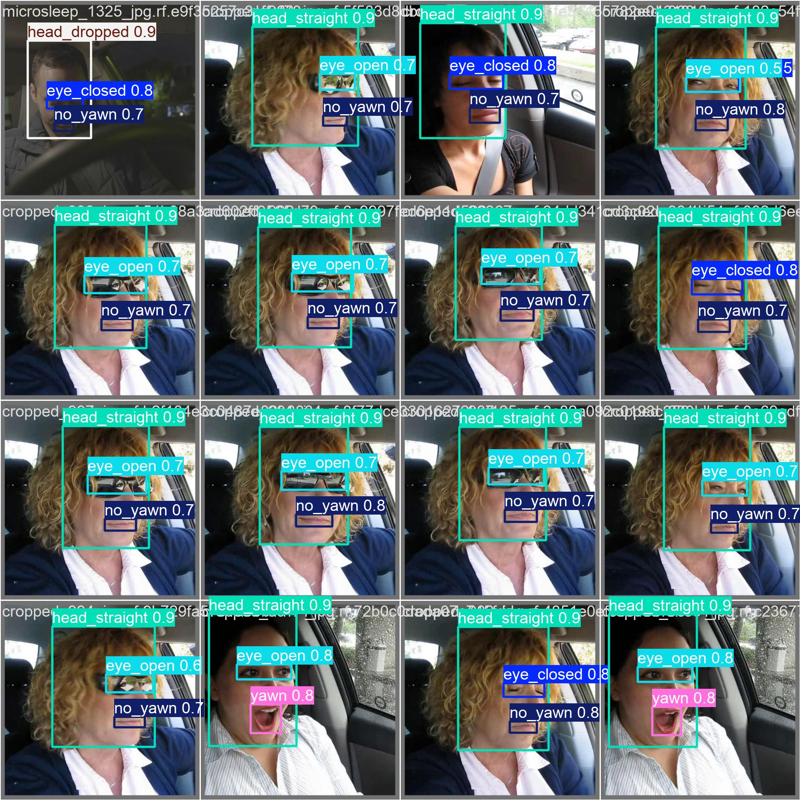

In [35]:
from PIL import Image
from IPython.display import display

img = Image.open("runs/detect/Driver_Drowsiness/epochs_20_adamw/val_batch0_pred.jpg")
img.thumbnail((800, 800))
display(img)


=== epochs_10_adamw ===


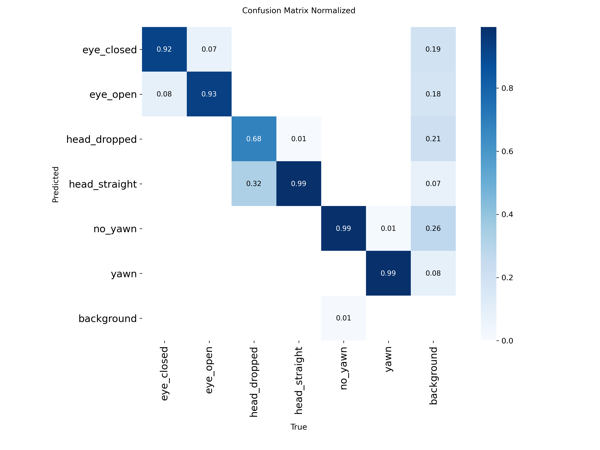


=== epochs_20_adamw ===


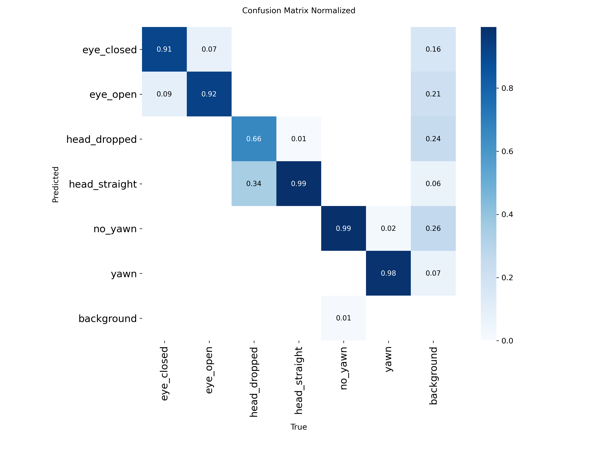


=== epochs_30_adamw ===


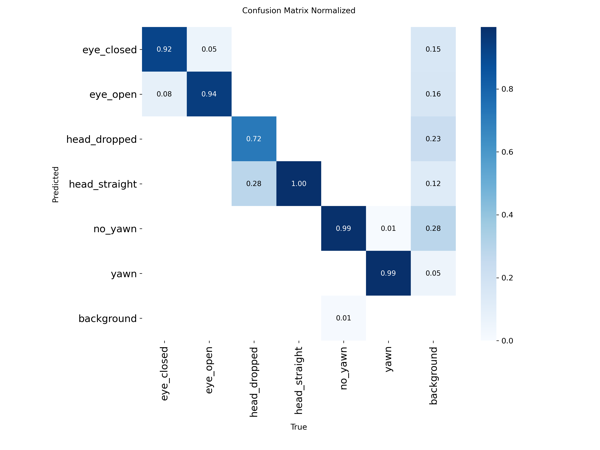

In [34]:
from PIL import Image
from IPython.display import display

for name in ["epochs_10_adamw", "epochs_20_adamw", "epochs_30_adamw"]:
    print(f"\n=== {name} ===")
    img = Image.open(f"runs/detect/Driver_Drowsiness/{name}/confusion_matrix_normalized.png")
    img.thumbnail((600, 600))
    display(img)

####Nicole — Batch Size
Baseline batch size: 8

Batch size values to test:
4
16
30

In [37]:
model_batch4 = YOLO("yolov8s.pt")

results_batch4 = model_batch4.train(
    data=str(dataset_path / "data.yaml"),
    epochs=5,
    patience=5,
    batch=4,
    lr0=0.0005,
    optimizer="AdamW",
    imgsz=640,
    device="cuda",
    workers=0,
    project="Driver_Drowsiness",
    name="batch_4_adamw",
    seed=42
)

Ultralytics 8.4.204  Python-3.10.3 torch-2.7.1+cu118 CUDA:0 (NVIDIA GeForce GTX 1660 SUPER, 6144MiB)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=4, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=dataset\data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=5, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.0005, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8s.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=batch_4_adamw-2, nbs=64, nms=None, opset=None, optimiz

In [38]:
model_batch16 = YOLO("yolov8s.pt")

results_batch16 = model_batch16.train(
    data=str(dataset_path / "data.yaml"),
    epochs=5,
    patience=5,
    batch=16,  # Changed to 16
    lr0=0.0005,
    optimizer="AdamW",
    imgsz=640,
    device="cuda",
    workers=0,
    project="Driver_Drowsiness",
    name="batch_16_adamw",
    seed=42
)

Ultralytics 8.4.204  Python-3.10.3 torch-2.7.1+cu118 CUDA:0 (NVIDIA GeForce GTX 1660 SUPER, 6144MiB)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=dataset\data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=5, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.0005, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8s.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=batch_16_adamw, nbs=64, nms=None, opset=None, optimiz

In [39]:
model_batch30 = YOLO("yolov8s.pt")

results_batch30 = model_batch30.train(
    data=str(dataset_path / "data.yaml"),
    epochs=5,
    patience=5,
    batch=30,
    lr0=0.0005,
    optimizer="AdamW",
    imgsz=640,
    device="cuda",
    workers=0,
    project="Driver_Drowsiness",
    name="batch_30_adamw",
    seed=42
)

Ultralytics 8.4.204  Python-3.10.3 torch-2.7.1+cu118 CUDA:0 (NVIDIA GeForce GTX 1660 SUPER, 6144MiB)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=30, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=dataset\data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=5, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.0005, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8s.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=batch_30_adamw, nbs=64, nms=None, opset=None, optimiz

In [40]:
!pip install pandas
import pandas as pd
from pathlib import Path

results_dir = Path("runs/detect/Driver_Drowsiness")

experiments = {
    "batch_4_adamw-2": 4,
    "batch_16_adamw": 16,
    "batch_30_adamw": 30
}

results = []

for name, bs in experiments.items():
    df = pd.read_csv(results_dir / name / "results.csv")
    df.columns = df.columns.str.strip()
    best = df.loc[df["metrics/mAP50-95(B)"].idxmax()]
    results.append({"Batch Size": bs, "Precision": round(best["metrics/precision(B)"], 4), "Recall": round(best["metrics/recall(B)"], 4), "mAP50": round(best["metrics/mAP50(B)"], 4), "mAP50-95": round(best["metrics/mAP50-95(B)"], 4)})

results_df = pd.DataFrame(results)

display(
    results_df.style
    .format({
        "Precision": "{:.3f}",
        "Recall": "{:.3f}",
        "mAP50": "{:.3f}",
        "mAP50-95": "{:.3f}"
    })
    .set_table_styles([
        {"selector": "tbody tr:nth-child(even)", "props": [("background-color", "#f2f2f2")]},
        {"selector": "td", "props": [("padding", "10px 18px"), ("text-align", "center")]}
    ])
)

You should consider upgrading via the 'C:\Users\liang\AppData\Local\Programs\Python\Python310\python.exe -m pip install --upgrade pip' command.


,Batch Size,Precision,Recall,mAP50,mAP50-95
0,4,0.914,0.915,0.942,0.648
1,16,0.927,0.921,0.956,0.640
2,30,0.919,0.917,0.956,0.640


####Zainab — Image Size (imgsz)

Baseline imgsz: 640

Image size values to test:
- 416
- 512
- 800


In [41]:
# Image size 416
model = YOLO("yolov8s.pt")
model.train(
    data=str(dataset_path / "data.yaml"),
    epochs=5,
    patience=5,
    batch=8,
    lr0=0.0005,
    optimizer="AdamW",
    imgsz=416,
    device="cuda",
    workers=0,
    project="Driver_Drowsiness",
    name="imgsz_416_adamw",
    seed=42
)

Ultralytics 8.4.204  Python-3.10.3 torch-2.7.1+cu118 CUDA:0 (NVIDIA GeForce GTX 1660 SUPER, 6144MiB)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=dataset\data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=5, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=416, iou=0.7, kobj=1.0, line_width=None, lr0=0.0005, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8s.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=imgsz_416_adamw, nbs=64, nms=None, opset=None, optimiz

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([0, 1, 2, 3, 4, 5])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x000002661BDB0460>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.046046,    0.047047,
 

In [42]:
# Image size 512
model = YOLO("yolov8s.pt")
model.train(
    data=str(dataset_path / "data.yaml"),
    epochs=5,
    patience=5,
    batch=8,
    lr0=0.0005,
    optimizer="AdamW",
    imgsz=512,
    device="cuda",
    workers=0,
    project="Driver_Drowsiness",
    name="imgsz_512_adamw",
    seed=42
)

Ultralytics 8.4.204  Python-3.10.3 torch-2.7.1+cu118 CUDA:0 (NVIDIA GeForce GTX 1660 SUPER, 6144MiB)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=dataset\data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=5, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=512, iou=0.7, kobj=1.0, line_width=None, lr0=0.0005, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8s.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=imgsz_512_adamw, nbs=64, nms=None, opset=None, optimiz

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([0, 1, 2, 3, 4, 5])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x000002664A7F45E0>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.046046,    0.047047,
 

In [43]:
# Image size 800
model = YOLO("yolov8s.pt")
model.train(
    data=str(dataset_path / "data.yaml"),
    epochs=5,
    patience=5,
    batch=8,
    lr0=0.0005,
    optimizer="AdamW",
    imgsz=800,
    device="cuda",
    workers=0,
    project="Driver_Drowsiness",
    name="imgsz_800_adamw",
    seed=42
)

Ultralytics 8.4.204  Python-3.10.3 torch-2.7.1+cu118 CUDA:0 (NVIDIA GeForce GTX 1660 SUPER, 6144MiB)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=dataset\data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=5, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=800, iou=0.7, kobj=1.0, line_width=None, lr0=0.0005, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8s.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=imgsz_800_adamw, nbs=64, nms=None, opset=None, optimiz

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([0, 1, 2, 3, 4, 5])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x00000266398BC190>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.046046,    0.047047,
 

In [44]:
!pip install pandas
import pandas as pd
from pathlib import Path

results_dir = Path("runs/detect/Driver_Drowsiness")

experiments = {
    "imgsz_416_adamw": 416,
    "imgsz_512_adamw": 512,
    "imgsz_800_adamw": 800
}

results = []

for name, sz in experiments.items():
    df = pd.read_csv(results_dir / name / "results.csv")
    df.columns = df.columns.str.strip()
    best = df.loc[df["metrics/mAP50-95(B)"].idxmax()]
    results.append({"Image Size": sz, "Precision": round(best["metrics/precision(B)"], 4), "Recall": round(best["metrics/recall(B)"], 4), "mAP50": round(best["metrics/mAP50(B)"], 4), "mAP50-95": round(best["metrics/mAP50-95(B)"], 4)})

results_df = pd.DataFrame(results)

display(
    results_df.style
    .format({
        "Precision": "{:.3f}",
        "Recall": "{:.3f}",
        "mAP50": "{:.3f}",
        "mAP50-95": "{:.3f}"
    })
    .set_table_styles([
        {"selector": "tbody tr:nth-child(even)", "props": [("background-color", "#f2f2f2")]},
        {"selector": "td", "props": [("padding", "10px 18px"), ("text-align", "center")]}
    ])
)

You should consider upgrading via the 'C:\Users\liang\AppData\Local\Programs\Python\Python310\python.exe -m pip install --upgrade pip' command.


,Image Size,Precision,Recall,mAP50,mAP50-95
0,416,0.928,0.908,0.947,0.636
1,512,0.915,0.925,0.951,0.639
2,800,0.909,0.928,0.955,0.638
